In [1]:
import numpy as np
import matplotlib.pyplot as plt

import qnmfits
import qnm
import sxs

In [2]:
_ksc = qnm.modes_cache

In [3]:
sim = sxs.load("SXS:BBH:0305v1.5")

Mf = sim.metadata.remnant_mass
chif = sim.metadata.remnant_dimensionless_spin
chif_mag = np.linalg.norm(chif)

Loading SXS simulations using latest tag 'v3.0.0', published at 2025-05-14T18:17:30Z.


In [4]:
sim.h.t -= sim.h.t[sim.h.data[:, sim.h.index(2,2)].argmax()]

In [5]:
frequencies = []
for n in range(7+1):
    mode_seq = _ksc(-2, 2, 2, n)
    Momega, _, C = mode_seq(chif_mag, store=True)
    frequencies.append(Momega/Mf)

In [6]:
mm_dict = {}
t0_list = np.linspace(-10, 50, 61)
for n in range(7+1):
    mm_dict[n] = []
    for t0 in t0_list:
        fit_result = qnmfits.lsq.fit(
            times=sim.h.t,
            data=sim.h.data[:, sim.h.index(2,2)],
            frequencies=frequencies[:n+1],
            t0=t0,
            T=100,
            t0_method="geq",
        )
        mm_dict[n].append(fit_result["mismatch"])

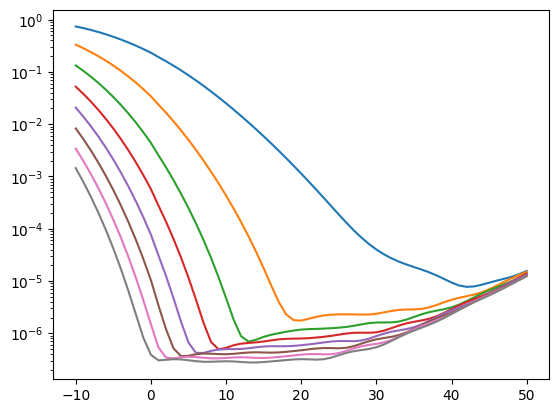

In [7]:
fig, ax = plt.subplots()
ax.set_yscale("log")

for n in range(7+1):
    ax.plot(t0_list, mm_dict[n])